In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns
from scipy.stats import skew, kurtosis

## Etude HC

In [ ]:
# Importer le fichier Excel
data1 = pd.read_excel("E:/données HC 1.xlsx")
data1.isnull()

,HC,Unnamed: 1,HC.1,Unnamed: 3,HC.2,Unnamed: 5,HC.3,Unnamed: 7,HC.4,Unnamed: 9,...,HC.30,Unnamed: 61,HC.31,Unnamed: 63,HC.32,Unnamed: 65,HC.33,Unnamed: 67,HC.34,Unnamed: 69
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1955,True,False,False,False,False,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1956,True,False,False,False,False,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1957,True,False,False,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1958,True,False,False,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


<Axes: >

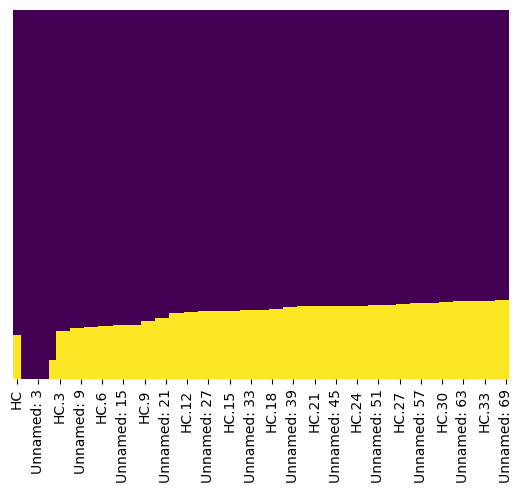

In [ ]:
sns.heatmap(data1.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [ ]:
data1.shape

(1960, 70)

In [ ]:
df_subset = data1.iloc[1:]

In [ ]:
df_subset.fillna(df_subset.median(), inplace=True)

C:\Users\nadam\AppData\Local\Temp\ipykernel_107776\1047438655.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset.fillna(df_subset.median(), inplace=True)
C:\Users\nadam\AppData\Local\Temp\ipykernel_107776\1047438655.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset.fillna(df_subset.median(), inplace=True)


#### Calcul de corrélation

In [ ]:
df_subset.corr()

,HC,Unnamed: 1,HC.1,Unnamed: 3,HC.2,Unnamed: 5,HC.3,Unnamed: 7,HC.4,Unnamed: 9,...,HC.30,Unnamed: 61,HC.31,Unnamed: 63,HC.32,Unnamed: 65,HC.33,Unnamed: 67,HC.34,Unnamed: 69
HC,1.000000,0.694238,0.835671,0.767817,0.871659,0.767408,0.969256,0.729681,0.823578,0.755819,...,0.856187,0.797924,0.902917,0.717417,0.942660,0.662713,0.907463,0.862034,0.931602,0.804593
Unnamed: 1,0.694238,1.000000,0.570796,0.591273,0.530207,0.550267,0.569999,0.520335,0.319186,0.394465,...,0.384659,0.536099,0.477876,0.495104,0.631947,0.693542,0.486780,0.548251,0.549034,0.517127
HC.1,0.835671,0.570796,1.000000,0.832612,0.910225,0.723653,0.872210,0.601636,0.843398,0.695724,...,0.829321,0.701405,0.833475,0.589901,0.788270,0.432968,0.834092,0.739756,0.825138,0.684630
Unnamed: 3,0.767817,0.591273,0.832612,1.000000,0.779615,0.636452,0.767694,0.588097,0.711292,0.541577,...,0.714669,0.648100,0.729382,0.560365,0.715082,0.456031,0.731787,0.697991,0.731772,0.601472
HC.2,0.871659,0.530207,0.910225,0.779615,1.000000,0.714471,0.904137,0.644194,0.864061,0.723130,...,0.853013,0.717527,0.860411,0.612056,0.819970,0.452968,0.861282,0.754074,0.854600,0.714513
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Unnamed: 65,0.662713,0.693542,0.432968,0.456031,0.452968,0.494124,0.554740,0.532677,0.297718,0.446350,...,0.438643,0.555358,0.532752,0.533295,0.703591,1.000000,0.546737,0.638528,0.618152,0.594691
HC.33,0.907463,0.486780,0.834092,0.731787,0.861282,0.706260,0.947554,0.702768,0.898731,0.823662,...,0.981664,0.834210,0.997818,0.729089,0.954668,0.546737,1.000000,0.883939,0.990681,0.835469
Unnamed: 67,0.862034,0.548251,0.739756,0.697991,0.754074,0.668181,0.853582,0.674610,0.735123,0.704017,...,0.837923,0.780687,0.880571,0.682761,0.910777,0.638528,0.883939,1.000000,0.903014,0.788959
HC.34,0.931602,0.549034,0.825138,0.731772,0.854600,0.725529,0.948564,0.711146,0.858554,0.818360,...,0.957887,0.849299,0.986634,0.741684,0.982726,0.618152,0.990681,0.903014,1.000000,0.844614


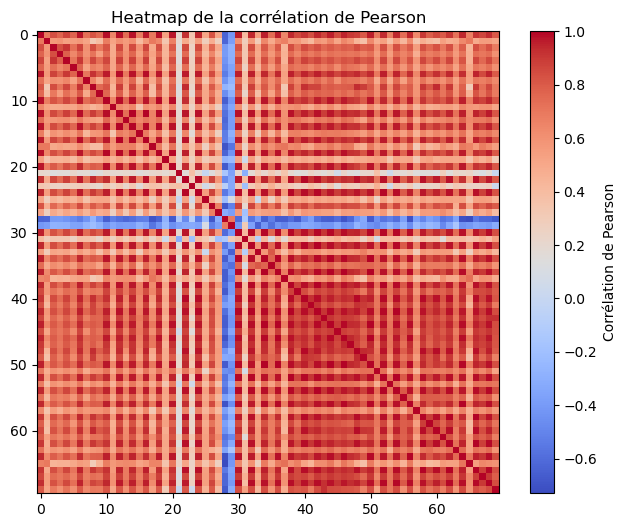

In [ ]:
# Calculer la corrélation de Pearson
correlation_matrix = np.corrcoef(df_subset, rowvar=False)

# Créer une heatmap
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Corrélation de Pearson')
plt.title('Heatmap de la corrélation de Pearson')
plt.show()

In [ ]:

# Convertir la matrice de corrélation en une matrice NumPy
correlation_matrix_values = df_subset.corr().values

# Créer une copie de la matrice de corrélation sous forme de matrice
correlation_matrix_array = np.array(correlation_matrix_values)

print("Matrice de corrélation sous forme de matrice NumPy :")
print(correlation_matrix_array)

Matrice de corrélation sous forme de matrice NumPy :
[[1.         0.69423849 0.83567073 ... 0.86203374 0.93160188 0.80459294]
 [0.69423849 1.         0.57079612 ... 0.54825146 0.54903393 0.51712738]
 [0.83567073 0.57079612 1.         ... 0.73975614 0.82513751 0.68463041]
 ...
 [0.86203374 0.54825146 0.73975614 ... 1.         0.90301409 0.78895874]
 [0.93160188 0.54903393 0.82513751 ... 0.90301409 1.         0.84461437]
 [0.80459294 0.51712738 0.68463041 ... 0.78895874 0.84461437 1.        ]]


In [ ]:
liste_corr=[]
liste_corr.append(correlation_matrix_array[0,1])
for i in range (1,len(correlation_matrix_array)-1,2):
                liste_corr.append(correlation_matrix_array[i+1,i+2])

In [ ]:
data1.iloc[1:] = df_subset

<Axes: >

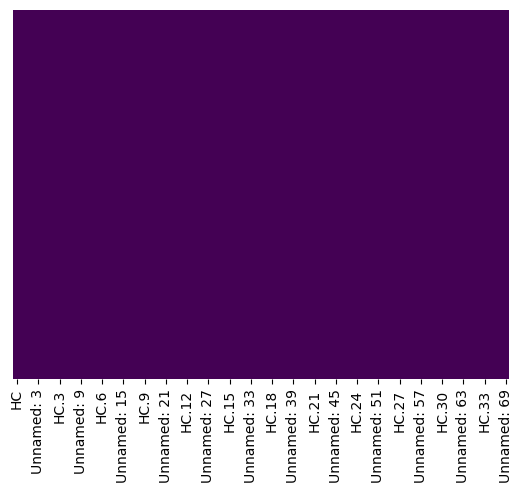

In [ ]:
sns.heatmap(data1.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [ ]:
data1.head()

,HC,Unnamed: 1,HC.1,Unnamed: 3,HC.2,Unnamed: 5,HC.3,Unnamed: 7,HC.4,Unnamed: 9,...,HC.30,Unnamed: 61,HC.31,Unnamed: 63,HC.32,Unnamed: 65,HC.33,Unnamed: 67,HC.34,Unnamed: 69
0,Cible_P1,Sujet_P1,Cible_P2,Sujet_P2,Cible_P3,Sujet_P3,Cible_P9,Sujet_P9,Cible_P11,Sujet_P11,...,Cible_P54,Sujet_P54,Cible_P55,Sujet_P55,Cible_P58,Sujet_P58,Cible_P59,Sujet_P59,Cible_P69,Sujet_P69
1,0.0,-96,0,-63.0,0.0,38.0,0.0,-518.0,0.0,506.0,...,0.0,108.0,0.0,411.0,0.0,94.0,0.0,223.0,0.0,247.0
2,280.0,-53,280,-63.0,280.0,38.0,0.0,-518.0,-165.0,512.0,...,0.0,109.0,280.0,406.0,0.0,94.0,0.0,227.0,280.0,250.0
3,138.0,-42,50,-63.0,59.0,38.0,84.0,-517.0,-23.0,508.0,...,59.0,108.0,59.0,398.0,146.0,305.0,67.0,225.0,100.0,254.0
4,153.0,-7,75,-63.0,75.0,38.0,100.0,-519.0,-6.0,514.0,...,75.0,108.0,75.0,403.0,160.0,300.0,84.0,226.0,116.0,252.0


#### Superposition de la cible avec la courbe du sujet

In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généralisation HC/figures_sup_HC" # Remplacez par le chemin de votre dossier
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)
# Tracer la superposition de deux colonnes consécutives à partir de la troisième ligne
for i in range(1, len(data1.columns), 2):
    #largeur_figure = 60  # Largeur de la figure en pouces
    #hauteur_figure = 6  # Hauteur de la figure en pouces
    #plt.figure(figsize=(largeur_figure, hauteur_figure))
    # Calculer le nombre total de points de données
    nombre_points = len(data1.iloc[1:, i-1])

    # Créer un tableau d'abscisses en secondes
    frequence_echantillonnage = 25  # Supposons une fréquence d'échantillonnage de 100 Hz
    temps = np.arange(nombre_points) / frequence_echantillonnage

    plt.plot(temps,data1.iloc[1:, i-1], label=data1.iat[0, i-1])
    plt.plot(temps,data1.iloc[1:, i], label=data1.iat[0, i])
    plt.legend()
    plt.xlabel('Temps (s)', fontsize=14)
    plt.ylabel('Amplitude', fontsize=14)

    #plt.title("Superposition du signal MOC d'un HC avec le signal de la cible", fontsize=14)
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i}_{i-1}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")

Les figures ont été enregistrées avec succès dans le dossier spécifié.


#### Calcule de décalage temporel et traçage de l'intercorrélation

In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généralisation HC/intercorrélation HC"  # Remplacez par le chemin de votre dossier
liste_delay=[] # liste de décalage temporel
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)

# Tracer la superposition de chaque deux colonnes consécutives
for i in range(1, len(data1.columns), 2):  # Parcours des colonnes par pas de 2
    plt.figure()  # Créer une nouvelle figure à chaque itération
    corr=np.correlate(data1.iloc[1:, i-1],data1.iloc[1:, i],mode='full')
    # Trouver l'index correspondant au décalage temporel maximal
    delay_index = np.argmax(corr)
    # Calculer le décalage temporel en fonction de l'index maximal
    M=max(len(data1.iloc[1:, i-1]),len(data1.iloc[1:, i]))
    delay =(M - delay_index)/25
    liste_delay.append(delay)
    # Création de l'axe des abscisses centré sur zéro
    x = np.arange(-len(corr)//2, len(corr)//2)
    # Tracé de la courbe d'intercorrélation centrée
    largeur_figure =30  # Largeur de la figure en pouces
    hauteur_figure = 6  # Hauteur de la figure en pouces

    plt.figure(figsize=(largeur_figure, hauteur_figure))
    plt.plot(x,corr)
    plt.grid(True)
    plt.xlabel('Décalage m',fontsize=12)
    plt.ylabel('Amplitude',fontsize=12)
    #plt.title("")
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i-1}_{i}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")

C:\Users\nadam\AppData\Local\Temp\ipykernel_107776\3718365681.py:23: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(largeur_figure, hauteur_figure))
C:\Users\nadam\AppData\Local\Temp\ipykernel_107776\3718365681.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()  # Créer une nouvelle figure à chaque itération


Les figures ont été enregistrées avec succès dans le dossier spécifié.


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

...

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

#### Détermination de la SFM

In [ ]:
liste_SFM=[]
for i in range(1,len(data1.columns)):
    if i % 2 != 0:

        # Calculer la Transformée de Fourier discrète (DFT) du signal
        dft = np.abs(np.fft.fft(data1.iloc[1:, i]))
        # Calculer la puissance spectrale
        power_spectrum = dft ** 2

        # Calculer la SFM
        geometric_mean = np.exp(np.mean(np.log(power_spectrum)))
        arithmetic_mean = np.mean(power_spectrum)
        spectral_flatness = geometric_mean / arithmetic_mean
        liste_SFM.append(spectral_flatness)

#### Etude de l'erreur

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généralisation HC/courbe d'erreur"  # Remplacez par le chemin de votre dossier
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)

liste_info_erreur = []


# Tracer la superposition de deux colonnes consécutives à partir de la troisième ligne
for i in range(1, len(data1.columns), 2):
    nombre_points = len(data1.iloc[1:, i-1])

    # Créer un tableau d'abscisses en secondes
    frequence_echantillonnage = 25  # Supposons une fréquence d'échantillonnage de 100 Hz
    temps = np.arange(nombre_points) / frequence_echantillonnage

    # Calcul de l'erreur entre les colonnes i-1 et i
    erreur = data1.iloc[1:, i-1] - data1.iloc[1:, i]
    erreur = erreur.apply(pd.to_numeric, errors='coerce')

    # Calcul des statistiques de l'erreur
    esperance = np.mean(erreur)
    variance = np.mean((erreur - esperance) ** 2)
    skewness = skew(erreur)
    kurt = kurtosis(erreur)
    liste_info_erreur.append((variance, esperance, skewness, kurt))

    # Tracer la courbe d'erreur
    plt.plot(temps,erreur)
    plt.xlabel('Temps (s)',fontsize=14)
    plt.ylabel("Amplitude",fontsize=14)
    #plt.title("Signal erreur entre le signal MOC d'un PD et le signal de la cible",fontsize=14)


    # Ajouter les valeurs calculées à la figure
    #plt.text(0.5, 0.9, f'Variance: {variance:.2f}', transform=plt.gca().transAxes)
    #plt.text(0.5, 0.85, f'Espérance (moyenne): {esperance:.2f}', transform=plt.gca().transAxes)
    #plt.text(0.5, 0.8, f'Skewness (asymétrie): {skewness:.2f}', transform=plt.gca().transAxes)
    #plt.text(0.5, 0.75, f'Kurtosis (aplatissement): {kurt:.2f}', transform=plt.gca().transAxes)
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i}_{i-1}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")


Les figures ont été enregistrées avec succès dans le dossier spécifié.


In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généralisation HC/Tf de l'erreur"  # Remplacez par le chemin de votre dossier
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)
# Tracer la superposition de deux colonnes consécutives à partir de la troisième ligne
for i in range(1, len(data1.columns), 2):
    # Calcul de l'erreur entre les colonnes i-1 et i
    erreur = data1.iloc[1:, i-1] - data1.iloc[1:, i]
    #erreur = erreur.apply(pd.to_numeric, errors='coerce')
    TF_erreur=np.fft.fft(erreur)
    # Tracer la courbe d'erreur
    plt.plot(TF_erreur)
    plt.xlabel('Index de la ligne')
    plt.ylabel('Valeurs')
    plt.title(f'Erreur entre {i} et {i-1}')
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i}_{i-1}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")


C:\Users\nadam\anaconda3\Lib\site-packages\matplotlib\cbook\__init__.py:1340: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Les figures ont été enregistrées avec succès dans le dossier spécifié.


#### Histogramme

In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures ="C:/Users/nadam/OneDrive/Bureau/Généralisation HC/hist" # Remplacez par le chemin de votre dossier
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)
# Tracer la superposition de deux colonnes consécutives à partir de la troisième ligne
for i in range(1, len(data1.columns),2):
    # Tracer l'histogramme
    plt.hist(data1.iloc[1:, i],color='skyblue', edgecolor='black')

    # Ajouter des titres et des étiquettes d'axes
    plt.title('Histogramme')
    plt.xlabel('Valeurs')
    plt.ylabel('Fréquence')

    plt.title(f'Histogramme num{i}')
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i}_{i-1}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")

Les figures ont été enregistrées avec succès dans le dossier spécifié.


## Etude PD

In [ ]:
# Importer le fichier Excel
data2 = pd.read_excel("E:/données PD final.xlsx")
data2.isnull()

,PD,Unnamed: 1,PD.1,Unnamed: 3,PD.2,Unnamed: 5,PD.3,Unnamed: 7,PD.4,Unnamed: 9,...,PD.25,Unnamed: 51,PD.26,Unnamed: 53,PD.27,Unnamed: 55,PD.28,Unnamed: 57,PD.29,Unnamed: 59
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1852,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1853,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1854,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
1855,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


<Axes: >

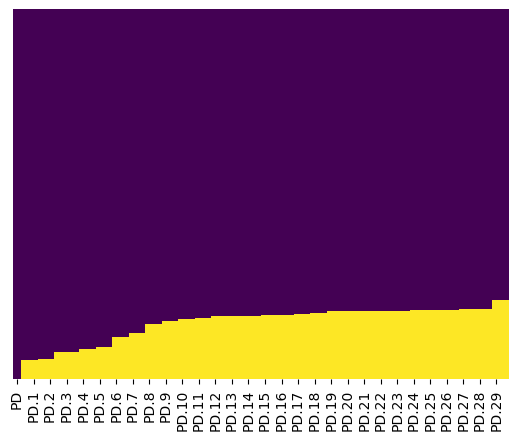

In [ ]:
sns.heatmap(data2.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [ ]:
data2.shape

(1857, 60)

In [ ]:
df_subset2 = data2.iloc[1:]

In [ ]:
df_subset2.fillna(df_subset2.median(), inplace=True)

C:\Users\nadam\AppData\Local\Temp\ipykernel_107776\563295851.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset2.fillna(df_subset2.median(), inplace=True)
C:\Users\nadam\AppData\Local\Temp\ipykernel_107776\563295851.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset2.fillna(df_subset2.median(), inplace=True)


In [ ]:
df_subset2.corr()

,PD,Unnamed: 1,PD.1,Unnamed: 3,PD.2,Unnamed: 5,PD.3,Unnamed: 7,PD.4,Unnamed: 9,...,PD.25,Unnamed: 51,PD.26,Unnamed: 53,PD.27,Unnamed: 55,PD.28,Unnamed: 57,PD.29,Unnamed: 59
PD,1.000000,0.402429,0.939427,0.720789,0.940606,0.536631,0.919222,0.517616,0.746339,0.119511,...,0.859457,0.647078,0.871316,0.476956,0.861884,0.665487,0.864029,0.659264,0.860046,0.370960
Unnamed: 1,0.402429,1.000000,0.441733,0.378210,0.427877,0.206740,0.452073,0.238742,0.385274,0.213017,...,0.340533,0.239007,0.348158,0.162567,0.340817,0.250181,0.342701,0.268460,0.342507,0.159182
PD.1,0.939427,0.441733,1.000000,0.757832,0.972304,0.572665,0.967439,0.547670,0.773157,0.136132,...,0.909390,0.681627,0.910966,0.488750,0.897320,0.683319,0.900294,0.698397,0.900712,0.385961
Unnamed: 3,0.720789,0.378210,0.757832,1.000000,0.754911,0.467176,0.743472,0.394602,0.599888,0.125254,...,0.748768,0.623419,0.763660,0.455666,0.754080,0.605693,0.754124,0.571989,0.756368,0.368876
PD.2,0.940606,0.427877,0.972304,0.754911,1.000000,0.568960,0.946844,0.538760,0.772813,0.157225,...,0.881360,0.662872,0.902451,0.497654,0.895309,0.697410,0.896927,0.678113,0.889690,0.386610
Unnamed: 5,0.536631,0.206740,0.572665,0.467176,0.568960,1.000000,0.576158,0.370009,0.372275,0.060099,...,0.618174,0.455851,0.589822,0.316175,0.567960,0.400552,0.570825,0.490963,0.580413,0.266602
PD.3,0.919222,0.452073,0.967439,0.743472,0.946844,0.576158,1.000000,0.586536,0.782473,0.149739,...,0.908007,0.675834,0.931397,0.502912,0.923564,0.717083,0.925020,0.705047,0.918321,0.401726
Unnamed: 7,0.517616,0.238742,0.547670,0.394602,0.538760,0.370009,0.586536,1.000000,0.472904,0.142783,...,0.435650,0.315862,0.428198,0.200517,0.417854,0.289785,0.418911,0.336057,0.429718,0.183991
PD.4,0.746339,0.385274,0.773157,0.599888,0.772813,0.372275,0.782473,0.472904,1.000000,0.210507,...,0.669295,0.520307,0.742731,0.484359,0.761414,0.653618,0.760915,0.483441,0.754509,0.475814
Unnamed: 9,0.119511,0.213017,0.136132,0.125254,0.157225,0.060099,0.149739,0.142783,0.210507,1.000000,...,0.066180,0.015038,0.093464,0.191540,0.106649,0.058798,0.095006,0.104760,0.120300,0.083448


In [ ]:

# Convertir la matrice de corrélation en une matrice NumPy
correlation_matrix_values2 = df_subset2.corr().values

# Créer une copie de la matrice de corrélation sous forme de matrice
correlation_matrix_array2 = np.array(correlation_matrix_values2)

print("Matrice de corrélation sous forme de matrice NumPy :")
print(correlation_matrix_array2)

Matrice de corrélation sous forme de matrice NumPy :
[[1.         0.40242945 0.93942673 ... 0.65926389 0.86004588 0.37095956]
 [0.40242945 1.         0.441733   ... 0.26846013 0.34250748 0.15918206]
 [0.93942673 0.441733   1.         ... 0.69839742 0.90071243 0.38596064]
 ...
 [0.65926389 0.26846013 0.69839742 ... 1.         0.77603384 0.30948871]
 [0.86004588 0.34250748 0.90071243 ... 0.77603384 1.         0.43692249]
 [0.37095956 0.15918206 0.38596064 ... 0.30948871 0.43692249 1.        ]]


In [ ]:
liste_corr2=[]
liste_corr2.append(correlation_matrix_array2[0,1])
for i in range (1,len(correlation_matrix_array2)-1,2):
                liste_corr2.append(correlation_matrix_array2[i+1,i+2])

In [ ]:
len(liste_corr2)

30

In [ ]:
data2.iloc[1:] = df_subset2
# Sélectionner les 70 premières colonnes
data22 = data2.iloc[:, :70]

<Axes: >

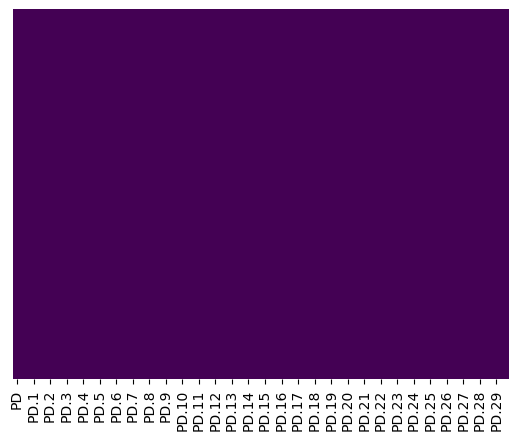

In [ ]:
sns.heatmap(data22.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [ ]:
data22.head()

,PD,Unnamed: 1,PD.1,Unnamed: 3,PD.2,Unnamed: 5,PD.3,Unnamed: 7,PD.4,Unnamed: 9,...,PD.25,Unnamed: 51,PD.26,Unnamed: 53,PD.27,Unnamed: 55,PD.28,Unnamed: 57,PD.29,Unnamed: 59
0,Cible_P4,Sujet_P4,Cible_P5,Sujet_P5,Cible_P6,Sujet_P6,Cible_P7,Sujet_P7,Cible_P8,Sujet_P8,...,Cible_P63_OFF,Sujet_P63_OFF,Cible_P64_OFF,Sujet_P64_OFF,Cible_P65_OFF,Sujet_P65_OFF,Cible_P66_OFF,Sujet_P66_OFF,Cible_P68_OFF,Sujet_P68_OFF
1,0,-8.0,0.0,66.0,0.0,-45.0,0.0,-76.0,0.0,686.0,...,0.0,120.0,0.0,115.0,0.0,-175.0,0.0,247.0,0.0,-80.0
2,280,-10.0,280.0,66.0,280.0,-47.0,280.0,-76.0,280.0,686.0,...,280.0,120.0,0.0,113.0,280.0,-175.0,280.0,247.0,0.0,-80.0
3,84,-10.0,100.0,65.0,75.0,-47.0,75.0,-76.0,100.0,-545.0,...,138.0,129.0,50.0,115.0,34.0,-148.0,42.0,244.0,92.0,-31.0
4,108,-10.0,116.0,41.0,100.0,-48.0,92.0,-77.0,116.0,-642.0,...,160.0,125.0,75.0,76.0,59.0,-148.0,59.0,246.0,108.0,-30.0


#### Superposition de la cible avec la courbe du sujet

In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généraisation PD/figures_sup_PD" # Remplacez par le chemin de votre dossier
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)
# Tracer la superposition de deux colonnes consécutives à partir de la troisième ligne
for i in range(1, len(data22.columns), 2):
    #largeur_figure = 60  # Largeur de la figure en pouces
    #hauteur_figure = 6  # Hauteur de la figure en pouces
    #plt.figure(figsize=(largeur_figure, hauteur_figure))
    nombre_points = len(data22.iloc[1:, i-1])

    # Créer un tableau d'abscisses en secondes
    frequence_echantillonnage = 25  # Supposons une fréquence d'échantillonnage de 100 Hz
    temps = np.arange(nombre_points) / frequence_echantillonnage

    plt.plot(temps,data22.iloc[1:, i-1], label=data22.iat[0, i-1])
    plt.plot(temps,data22.iloc[1:, i], label=data22.iat[0, i])
    plt.legend()
    plt.xlabel('Temps (s)', fontsize=14)
    plt.ylabel('Variation de la position de la pupille ', fontsize=14)

    #plt.title("Superposition du signal MOC d'un PD avec le signal de la cible", fontsize=14)
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i}_{i-1}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")

Les figures ont été enregistrées avec succès dans le dossier spécifié.


#### Calcule de décalage temporel et traçage de l'intercorrélation

In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généraisation PD/intercorrélation PD"  # Remplacez par le chemin de votre dossier
liste_delay2=[] # liste de décalage temporel
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)

# Tracer la superposition de chaque deux colonnes consécutives
for i in range(1, len(data22.columns), 2):  # Parcours des colonnes par pas de 2
    plt.figure()  # Créer une nouvelle figure à chaque itération
    corr=np.correlate(data22.iloc[1:, i-1],data22.iloc[1:, i],mode='full')
    # Trouver l'index correspondant au décalage temporel maximal
    delay_index = np.argmax(corr)
    # Calculer le décalage temporel en fonction de l'index maximal
    M=max(len(data22.iloc[1:, i-1]),len(data22.iloc[1:, i]))
    delay =(M - delay_index)/25
    liste_delay2.append(delay)
    plt.plot(corr)
    plt.xlabel('décalage')
    plt.ylabel('Valeurs')
    plt.title(f'intercorrélation de {i-1} avec la colonne {i}')
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i-1}_{i}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")

Les figures ont été enregistrées avec succès dans le dossier spécifié.


#### Détermination de la SFM

In [ ]:
liste_SFM2=[]
for i in range(1,len(data22.columns)):
    if i % 2 != 0:

        # Calculer la Transformée de Fourier discrète (DFT) du signal
        dft = np.abs(np.fft.fft(data22.iloc[1:, i]))
        # Calculer la puissance spectrale
        power_spectrum = dft ** 2

        # Calculer la SFM
        geometric_mean = np.exp(np.mean(np.log(power_spectrum)))
        arithmetic_mean = np.mean(power_spectrum)
        spectral_flatness = geometric_mean / arithmetic_mean
        liste_SFM2.append(spectral_flatness)

#### Etude de l'erreur

In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généraisation PD/courbe de l'erreur"  # Remplacez par le chemin de votre dossier
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)

liste_info_erreur2 = []

# Tracer la superposition de deux colonnes consécutives à partir de la troisième ligne
for i in range(1, len(data22.columns), 2):
    # Calcul de l'erreur entre les colonnes i-1 et i
    erreur = data22.iloc[1:, i-1] - data22.iloc[1:, i]
    erreur = erreur.apply(pd.to_numeric, errors='coerce')

    # Calcul des statistiques de l'erreur
    esperance = np.mean(erreur)
    variance = np.mean((erreur - esperance) ** 2)
    skewness = skew(erreur)
    kurt = kurtosis(erreur)
    liste_info_erreur2.append((variance, esperance, skewness, kurt))
    nombre_points = len(data22.iloc[1:, i-1])

    # Créer un tableau d'abscisses en secondes
    frequence_echantillonnage = 25  # Supposons une fréquence d'échantillonnage de 100 Hz
    temps = np.arange(nombre_points) / frequence_echantillonnage


    # Tracer la courbe d'erreur
    plt.plot(temps,erreur)
    plt.xlabel('Temps (s)',fontsize=14)
    plt.ylabel("Valeurs de l'erreur",fontsize=14)
    #plt.title("Signal erreur entre le signal MOC d'un PD et le signal de la cible",fontsize=14)

    # Ajouter les valeurs calculées à la figure
    #plt.text(0.5, 0.9, f'Variance: {variance:.2f}', transform=plt.gca().transAxes)
    #plt.text(0.5, 0.85, f'Espérance (moyenne): {esperance:.2f}', transform=plt.gca().transAxes)
    #plt.text(0.5, 0.8, f'Skewness (asymétrie): {skewness:.2f}', transform=plt.gca().transAxes)
    #plt.text(0.5, 0.75, f'Kurtosis (aplatissement): {kurt:.2f}', transform=plt.gca().transAxes)
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i}_{i-1}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")


Les figures ont été enregistrées avec succès dans le dossier spécifié.


In [ ]:
# Créer un dossier pour enregistrer les figures s'il n'existe pas déjà
dossier_figures = "C:/Users/nadam/OneDrive/Bureau/Généraisation PD/Tf d'erreur"  # Remplacez par le chemin de votre dossier
if not os.path.exists(dossier_figures):
    os.makedirs(dossier_figures)
# Tracer la superposition de deux colonnes consécutives à partir de la troisième ligne
for i in range(1, len(data22.columns), 2):
    # Calcul de l'erreur entre les colonnes i-1 et i
    erreur = data22.iloc[1:, i-1] - data22.iloc[1:, i]
    #erreur = erreur.apply(pd.to_numeric, errors='coerce')
    TF_erreur=np.fft.fft(erreur)
    # Tracer la courbe d'erreur
    plt.plot(TF_erreur)
    plt.xlabel('Index de la ligne')
    plt.ylabel('Valeurs')
    plt.title(f'Erreur entre {i} et {i-1}')
    # Enregistrer la figure avec un nom basé sur les colonnes
    nom_fichier = os.path.join(dossier_figures, f'figure_{i}_{i-1}.png')
    plt.savefig(nom_fichier)
    plt.close()  # Fermer la figure pour libérer la mémoire

print("Les figures ont été enregistrées avec succès dans le dossier spécifié.")

C:\Users\nadam\anaconda3\Lib\site-packages\matplotlib\cbook\__init__.py:1340: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Les figures ont été enregistrées avec succès dans le dossier spécifié.


### Test sur les descripteurs :

In [ ]:
########################## listes totales des descripteurs #################
SFM=[]
SFM=liste_SFM+liste_SFM2
delay=[]
delay=liste_delay+liste_delay2
info_erreur=[]
info_erreur=liste_info_erreur+liste_info_erreur2

#### HC

In [ ]:
var,esp,skew,kurt=[],[],[],[]
for i in range(len(liste_info_erreur)):
    var.append(liste_info_erreur[i][0])
    esp.append(liste_info_erreur[i][1])
    skew.append(liste_info_erreur[i][2])
    kurt.append(liste_info_erreur[i][3])

In [ ]:
################## test de normalité ######################
from scipy.stats import shapiro
stat, p_value = shapiro(liste_delay)

# Afficher les résultats du test
print("Statistique de test :", stat)
print("P-valeur :", p_value)

# Interpréter les résultats du test
alpha = 0.05  # Niveau de signification
if p_value > alpha:
    print("L'échantillon semble suivre une distribution normale (ne pas rejeter l'hypothèse nulle)")
else:
    print("L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)")


Statistique de test : 0.3370113968849182
P-valeur : 1.9937758041765896e-11
L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)


In [ ]:
from scipy.stats import shapiro

# Supposons que 'data' est votre échantillon de données
stat, p_value = shapiro(liste_SFM)

# Afficher les résultats du test
print("Statistique de test :", stat)
print("P-valeur :", p_value)

# Interpréter les résultats du test
alpha = 0.05  # Niveau de signification
if p_value > alpha:
    print("L'échantillon semble suivre une distribution normale (ne pas rejeter l'hypothèse nulle)")
else:
    print("L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)")


Statistique de test : 0.7842761874198914
P-valeur : 1.0182698133576196e-05
L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)


Text(0, 0.5, 'delay')

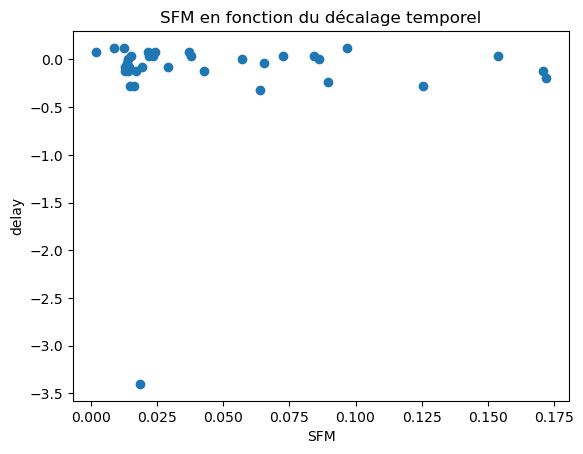

In [ ]:
plt.scatter(liste_SFM, liste_delay)
# Ajouter des titres et des labels d'axe
plt.title('SFM en fonction du décalage temporel')
plt.xlabel('SFM')
plt.ylabel('delay')

Text(0, 0.5, 'SFM')

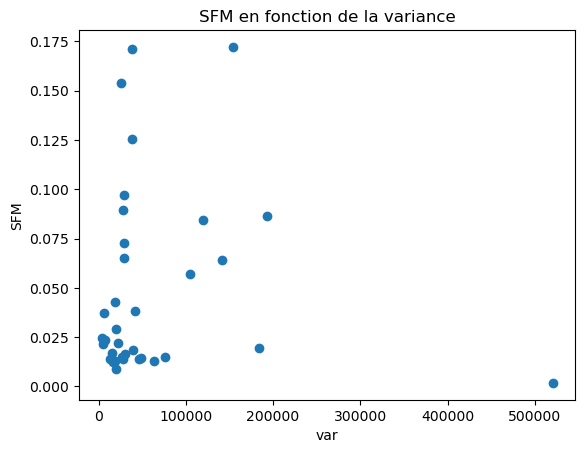

In [ ]:
plt.scatter(var, liste_SFM)
# Ajouter des titres et des labels d'axe
plt.title('SFM en fonction de la variance')
plt.xlabel('var')
plt.ylabel('SFM')

Text(0, 0.5, 'liste_delay')

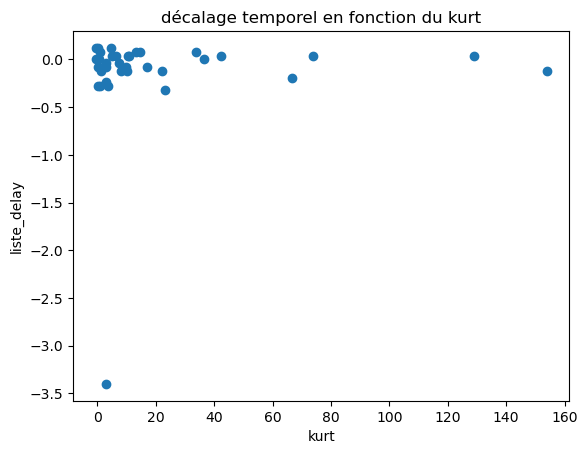

In [ ]:
plt.scatter(kurt,liste_delay)
# Ajouter des titres et des labels d'axe
plt.title('décalage temporel en fonction du kurt')
plt.xlabel('kurt')
plt.ylabel('liste_delay')

Text(0, 0.5, 'liste_SFM')

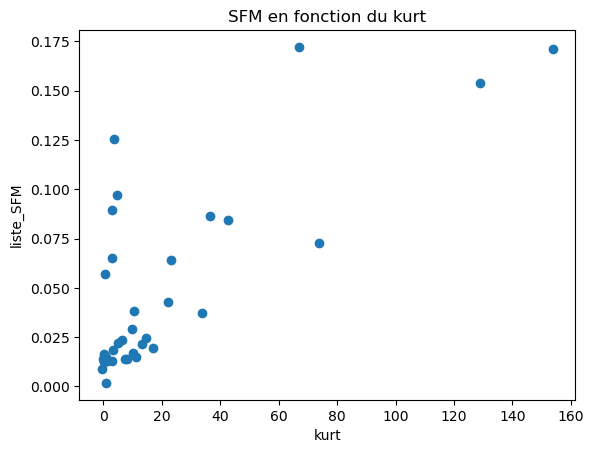

In [ ]:
plt.scatter(kurt, liste_SFM)
# Ajouter des titres et des labels d'axe
plt.title('SFM en fonction du kurt')
plt.xlabel('kurt')
plt.ylabel('liste_SFM')

Text(0, 0.5, 'liste_SFM')

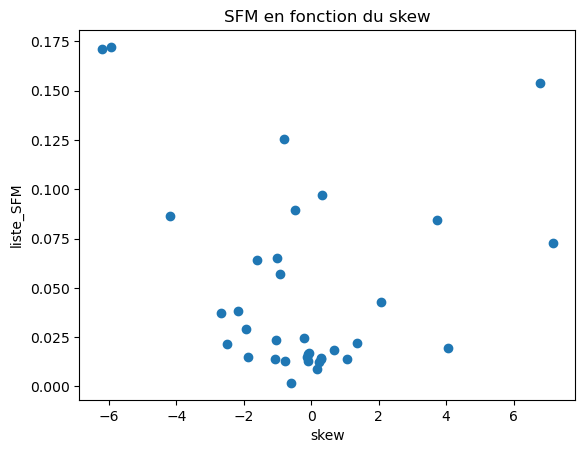

In [ ]:
plt.scatter(skew, liste_SFM)
# Ajouter des titres et des labels d'axe
plt.title('SFM en fonction du skew')
plt.xlabel('skew')
plt.ylabel('liste_SFM')

Text(0, 0.5, 'liste_dely')

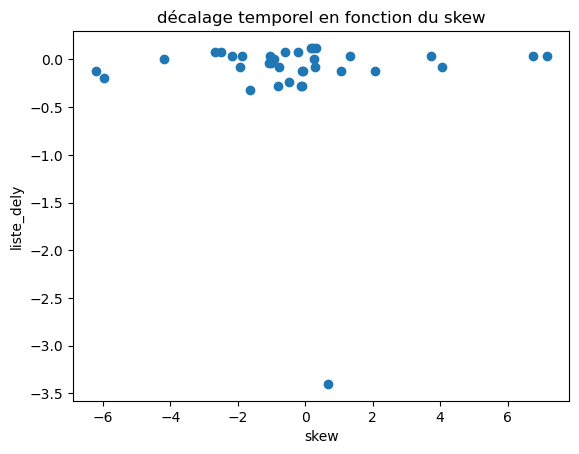

In [ ]:
plt.scatter(skew, liste_delay)
# Ajouter des titres et des labels d'axe
plt.title('décalage temporel en fonction du skew')
plt.xlabel('skew')
plt.ylabel('liste_dely')

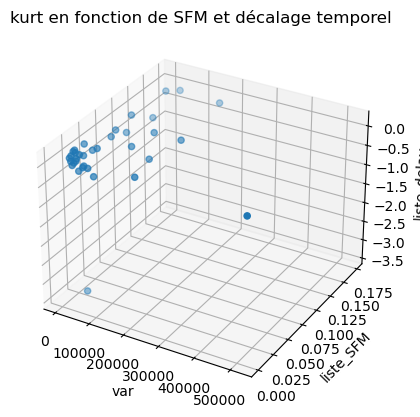

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
# Créer une figure 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
# Créer le nuage de points 3D
ax.scatter(var, liste_SFM, liste_delay)

# Ajouter des titres et des labels d'axe
ax.set_title('kurt en fonction de SFM et décalage temporel')
ax.set_xlabel('var')
ax.set_ylabel('liste_SFM')
ax.set_zlabel('liste_delay')

# Afficher le nuage de points 3D
plt.show()

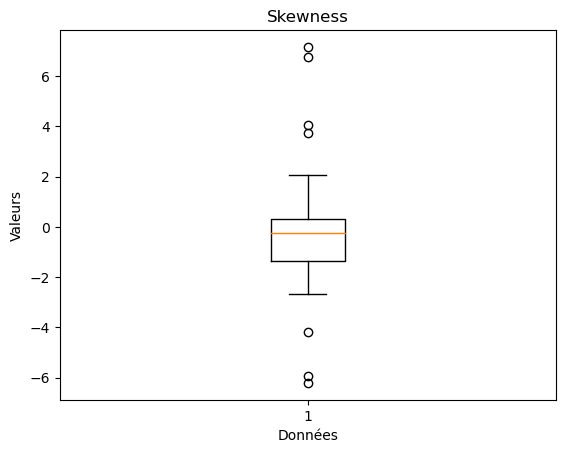

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(skew)
# Ajouter un titre et des labels d'axe
plt.title('Skewness')
plt.xlabel('Données')
plt.ylabel('Valeurs')

# Afficher le graphique
plt.show()


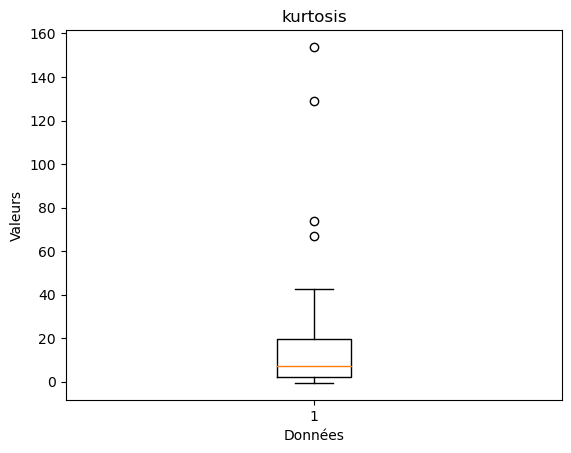

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(kurt)
# Ajouter un titre et des labels d'axe
plt.title('kurtosis')
plt.xlabel('Données')
plt.ylabel('Valeurs')

# Afficher le graphique
plt.show()

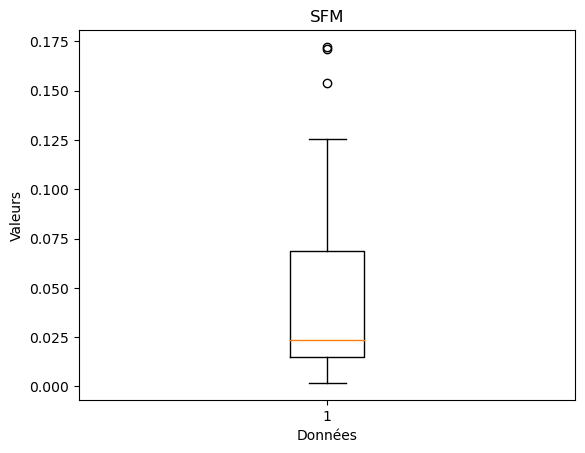

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(liste_SFM)
# Ajouter un titre et des labels d'axe
plt.title('SFM')
plt.xlabel('Données')
plt.ylabel('Valeurs')
# Afficher le graphique
plt.show()

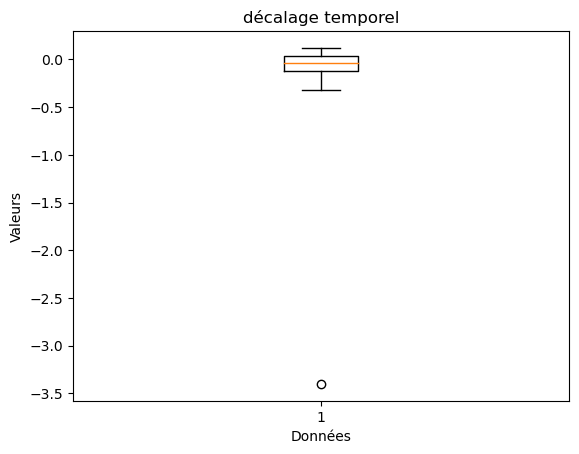

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(liste_delay)
# Ajouter un titre et des labels d'axe
plt.title('décalage temporel')
plt.xlabel('Données')
plt.ylabel('Valeurs')

# Afficher le graphique
plt.show()

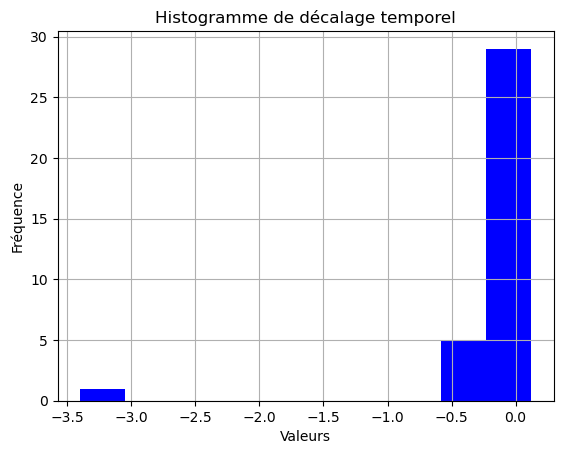

In [ ]:
# Tracer l'histogramme
plt.hist(liste_delay, color='blue')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.title('Histogramme de décalage temporel')
plt.grid(True)
plt.show()

#### PD

In [ ]:
var2,esp2,skew2,kurt2=[],[],[],[]
for i in range(len(liste_info_erreur2)):
    var2.append(liste_info_erreur2[i][0])
    esp2.append(liste_info_erreur2[i][1])
    skew2.append(liste_info_erreur2[i][2])
    kurt2.append(liste_info_erreur2[i][3])

In [ ]:
################## test de normalité ######################
from scipy.stats import shapiro
stat, p_value = shapiro(liste_delay2)

# Afficher les résultats du test
print("Statistique de test :", stat)
print("P-valeur :", p_value)

# Interpréter les résultats du test
alpha = 0.05  # Niveau de signification
if p_value > alpha:
    print("L'échantillon semble suivre une distribution normale (ne pas rejeter l'hypothèse nulle)")
else:
    print("L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)")


Statistique de test : 0.4138229489326477
P-valeur : 7.343306518414749e-10
L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)


In [ ]:
from scipy.stats import shapiro

# Supposons que 'data' est votre échantillon de données
stat, p_value = shapiro(liste_SFM2)

# Afficher les résultats du test
print("Statistique de test :", stat)
print("P-valeur :", p_value)

# Interpréter les résultats du test
alpha = 0.05  # Niveau de signification
if p_value > alpha:
    print("L'échantillon semble suivre une distribution normale (ne pas rejeter l'hypothèse nulle)")
else:
    print("L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)")


Statistique de test : 0.8291956186294556
P-valeur : 0.00023432407760992646
L'échantillon ne suit pas une distribution normale (rejeter l'hypothèse nulle)


Text(0, 0.5, 'delay')

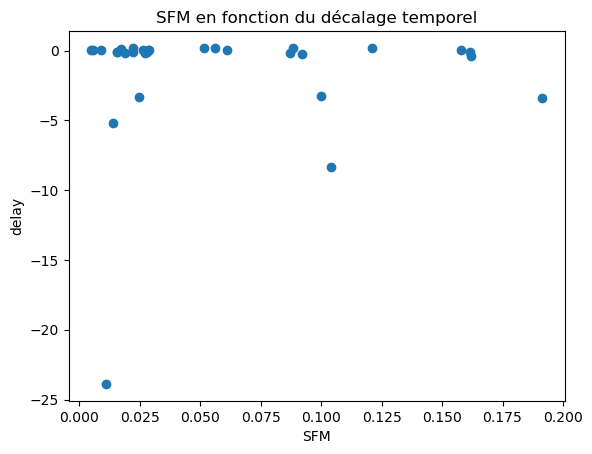

In [ ]:
plt.scatter(liste_SFM2, liste_delay2)
# Ajouter des titres et des labels d'axe
plt.title('SFM en fonction du décalage temporel')
plt.xlabel('SFM')
plt.ylabel('delay')

Text(0, 0.5, 'SFM')

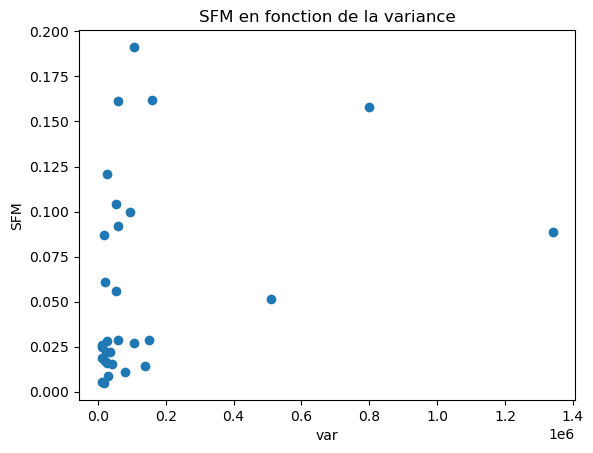

In [ ]:
plt.scatter(var2, liste_SFM2)
# Ajouter des titres et des labels d'axe
plt.title('SFM en fonction de la variance')
plt.xlabel('var')
plt.ylabel('SFM')

Text(0, 0.5, 'liste_delay')

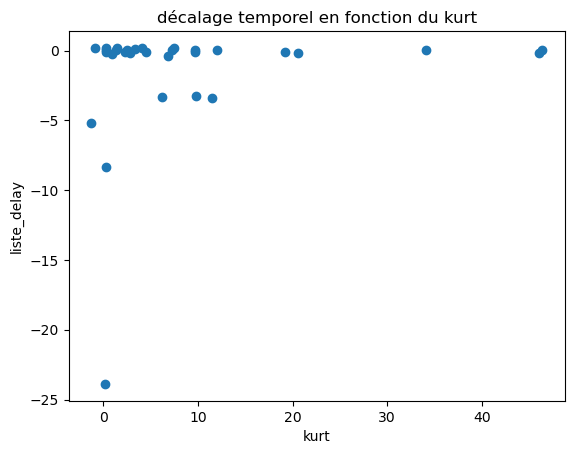

In [ ]:
plt.scatter(kurt2,liste_delay2)
# Ajouter des titres et des labels d'axe
plt.title('décalage temporel en fonction du kurt')
plt.xlabel('kurt')
plt.ylabel('liste_delay')

Text(0, 0.5, 'liste_SFM')

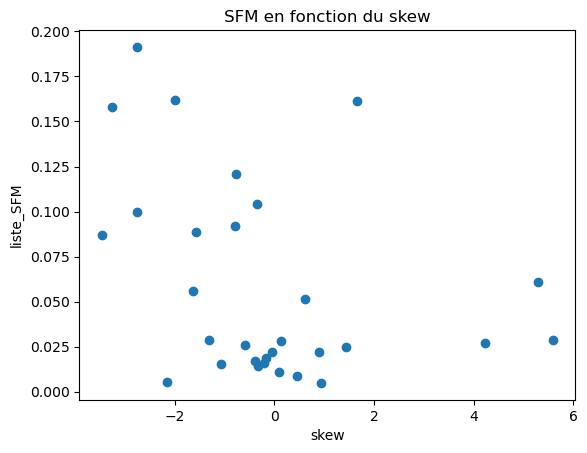

In [ ]:
plt.scatter(skew2, liste_SFM2)
# Ajouter des titres et des labels d'axe
plt.title('SFM en fonction du skew')
plt.xlabel('skew')
plt.ylabel('liste_SFM')

Text(0, 0.5, 'liste_dely')

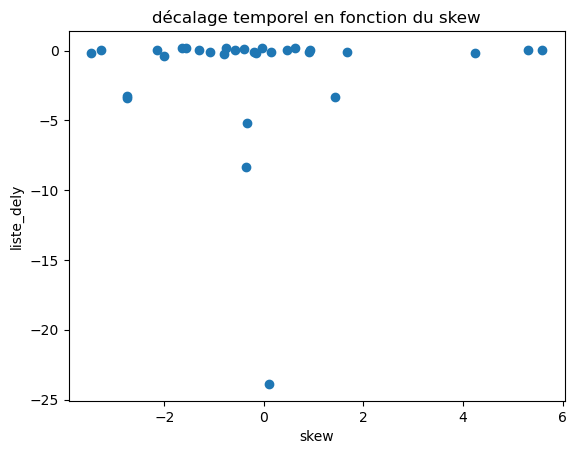

In [ ]:
plt.scatter(skew2, liste_delay2)
# Ajouter des titres et des labels d'axe
plt.title('décalage temporel en fonction du skew')
plt.xlabel('skew')
plt.ylabel('liste_dely')

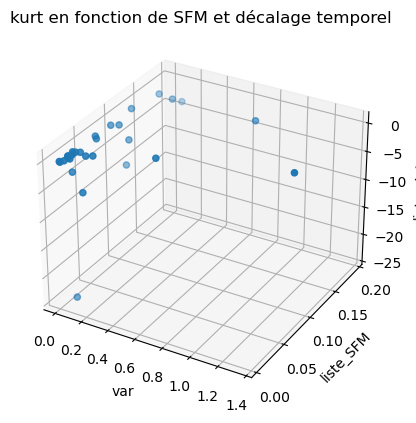

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
# Créer une figure 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
# Créer le nuage de points 3D
ax.scatter(var2, liste_SFM2, liste_delay2)

# Ajouter des titres et des labels d'axe
ax.set_title('kurt en fonction de SFM et décalage temporel')
ax.set_xlabel('var')
ax.set_ylabel('liste_SFM')
ax.set_zlabel('liste_delay')

# Afficher le nuage de points 3D
plt.show()

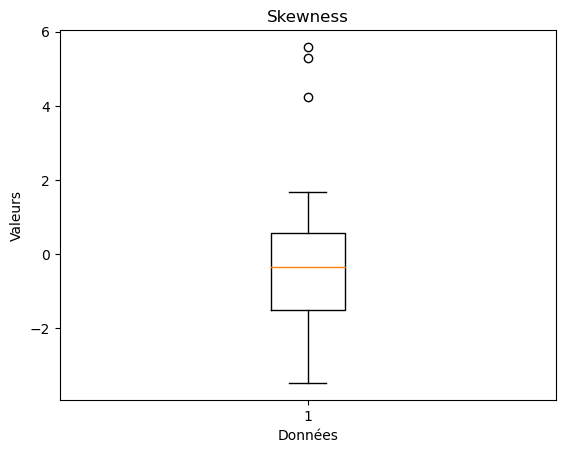

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(skew2)
# Ajouter un titre et des labels d'axe
plt.title('Skewness')
plt.xlabel('Données')
plt.ylabel('Valeurs')

# Afficher le graphique
plt.show()


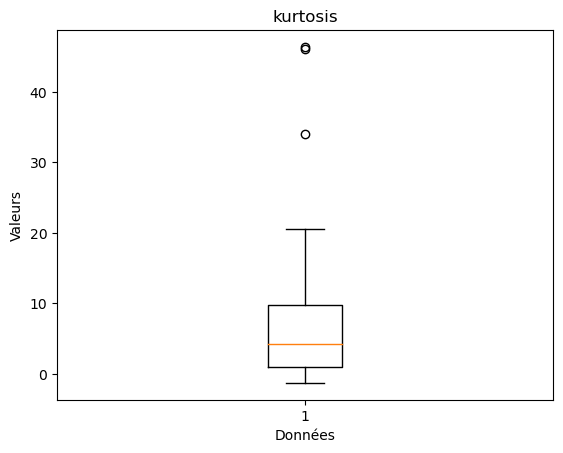

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(kurt2)
# Ajouter un titre et des labels d'axe
plt.title('kurtosis')
plt.xlabel('Données')
plt.ylabel('Valeurs')

# Afficher le graphique
plt.show()

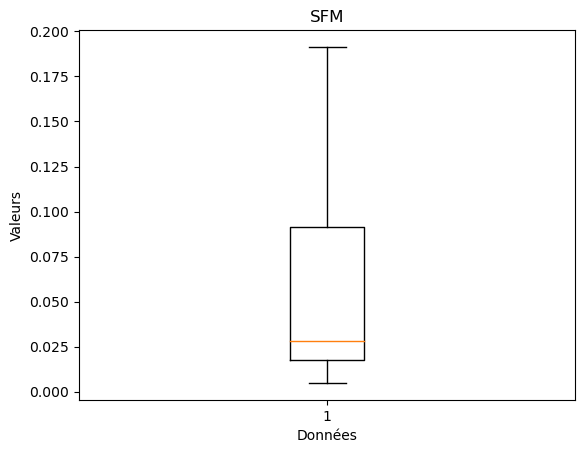

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(liste_SFM2)
# Ajouter un titre et des labels d'axe
plt.title('SFM')
plt.xlabel('Données')
plt.ylabel('Valeurs')
# Afficher le graphique
plt.show()

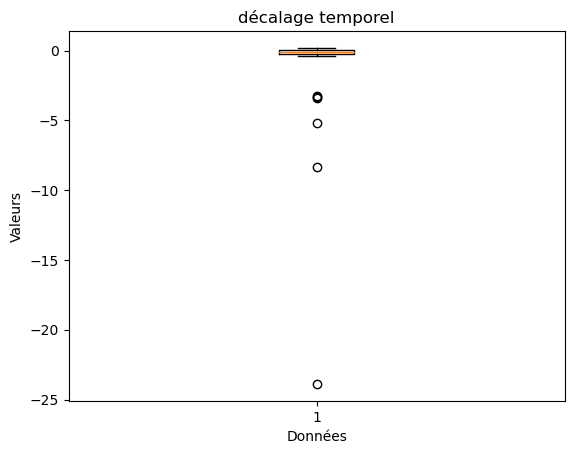

In [ ]:
# Tracer la boîte à moustaches
plt.boxplot(liste_delay2)
# Ajouter un titre et des labels d'axe
plt.title('décalage temporel')
plt.xlabel('Données')
plt.ylabel('Valeurs')

# Afficher le graphique
plt.show()

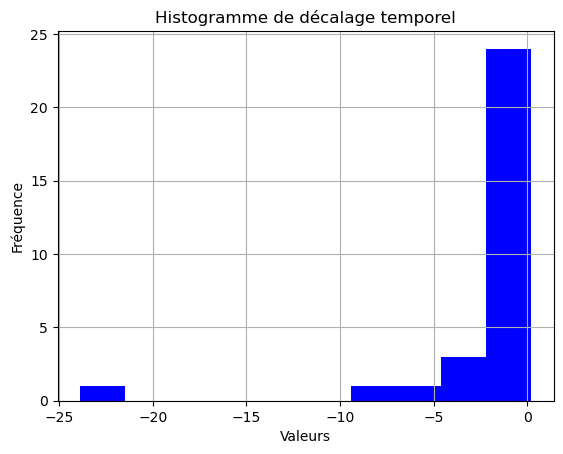

In [ ]:
# Tracer l'histogramme
plt.hist(liste_delay2, color='blue')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.title('Histogramme de décalage temporel')
plt.grid(True)
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure1.png")
plt.show()

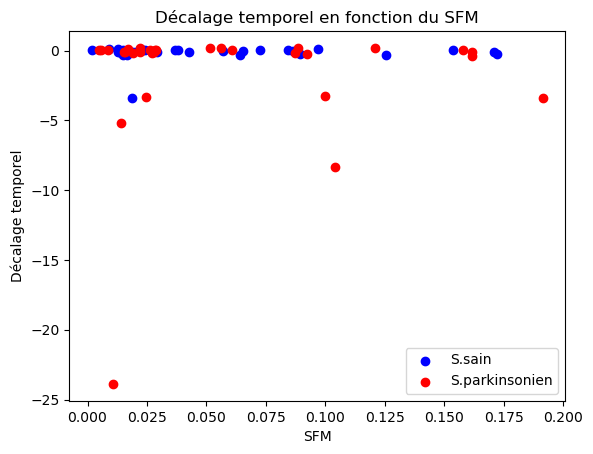

In [ ]:
# Tracer les courbes scatter
plt.scatter(liste_SFM, liste_delay, label='S.sain', color='blue')  # Courbe 1 en bleu
plt.scatter(liste_SFM2, liste_delay2, label='S.parkinsonien', color='red')   # Courbe 2 en rouge

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Décalage temporel en fonction du SFM')
plt.xlabel('SFM')
plt.ylabel('Décalage temporel')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure1.png")

# Afficher la figure
plt.show()

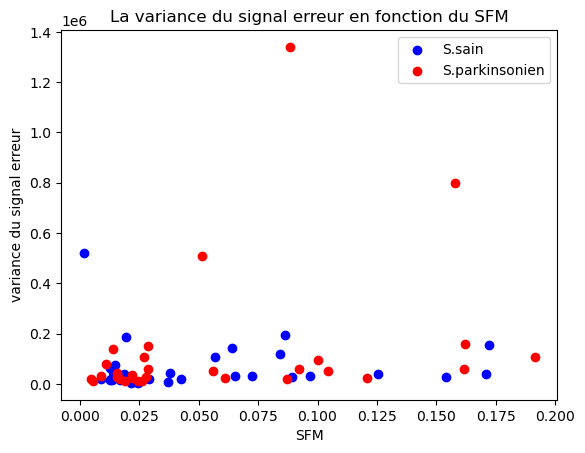

In [ ]:
# Tracer les courbes scatter
plt.scatter(liste_SFM, var, label='S.sain', color='blue')  # Courbe 1 en bleu
plt.scatter(liste_SFM2, var2, label='S.parkinsonien', color='red')   # Courbe 2 en rouge

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('La variance du signal erreur en fonction du SFM')
plt.xlabel('SFM')
plt.ylabel('variance du signal erreur')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure2.png")

# Afficher la figure
plt.show()

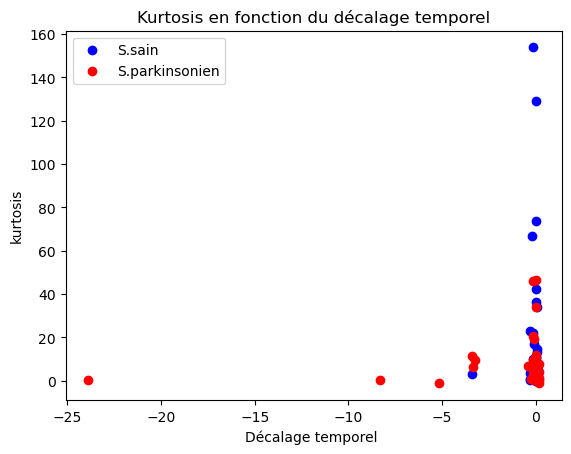

In [ ]:
# Tracer les courbes scatter
plt.scatter(liste_delay,kurt, label='S.sain', color='blue')  # Courbe 1 en bleu
plt.scatter(liste_delay2,kurt2, label='S.parkinsonien', color='red')   # Courbe 2 en rouge

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Kurtosis en fonction du décalage temporel')
plt.xlabel('Décalage temporel ')
plt.ylabel('kurtosis')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure3.png")

# Afficher la figure
plt.show()

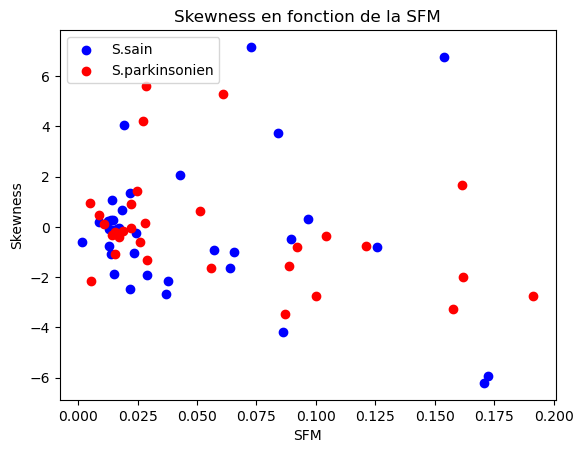

In [ ]:
# Tracer les courbes scatter
plt.scatter(liste_SFM,skew, label='S.sain', color='blue')  # Courbe 1 en bleu
plt.scatter(liste_SFM2,skew2, label='S.parkinsonien', color='red')   # Courbe 2 en rouge

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Skewness en fonction de la SFM')
plt.xlabel('SFM')
plt.ylabel('Skewness')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure4.png")

# Afficher la figure
plt.show()

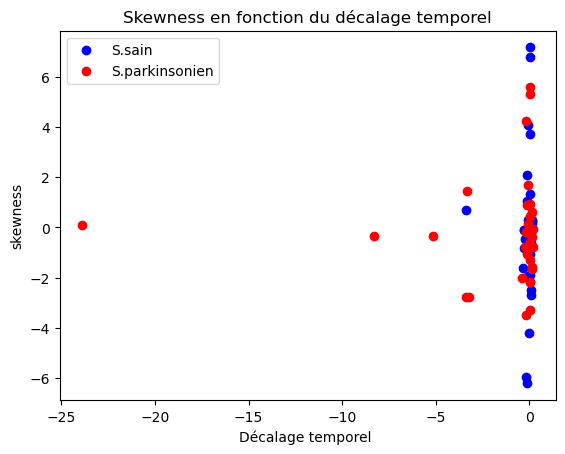

In [ ]:
# Tracer les courbes scatter
plt.scatter(liste_delay,skew, label='S.sain', color='blue')  # Courbe 1 en bleu
plt.scatter(liste_delay2,skew2, label='S.parkinsonien', color='red')   # Courbe 2 en rouge

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Skewness en fonction du décalage temporel')
plt.xlabel('Décalage temporel ')
plt.ylabel('skewness')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure5.png")

# Afficher la figure
plt.show()

In [ ]:
len(liste_delay)

35

In [ ]:
# Division de chaque élément de la liste par 35
liste_delay_divided = [delay / 35 for delay in liste_delay]


In [ ]:
len(liste_delay2)

30

In [ ]:
# Division de chaque élément de la liste par 35
liste_delay_divided2 = [delay / 30 for delay in liste_delay2]


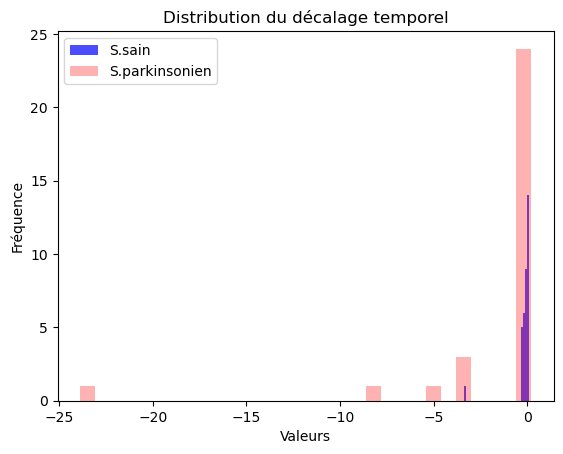

In [ ]:
# Tracer les histogrammes
plt.hist(liste_delay, bins=30, alpha=0.7, label='S.sain', color='blue')  # Histogramme 1
plt.hist(liste_delay2,bins=30, alpha=0.3, label='S.parkinsonien',color='red')  # Histogramme 2

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Distribution du décalage temporel')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure6.png")

# Afficher la figure
plt.show()

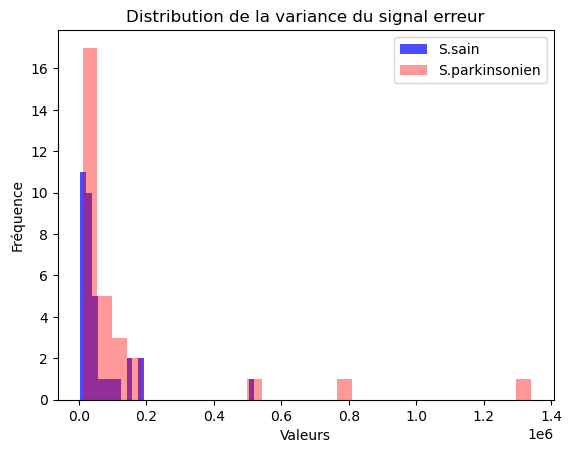

In [ ]:
# Tracer les histogrammes
plt.hist(var, bins=30, alpha=0.7, label='S.sain', color='blue')  # Histogramme 1
plt.hist(var2,bins=30, alpha=0.4, label='S.parkinsonien',color='red')  # Histogramme 2

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Distribution de la variance du signal erreur')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure7.png")

# Afficher la figure
plt.show()

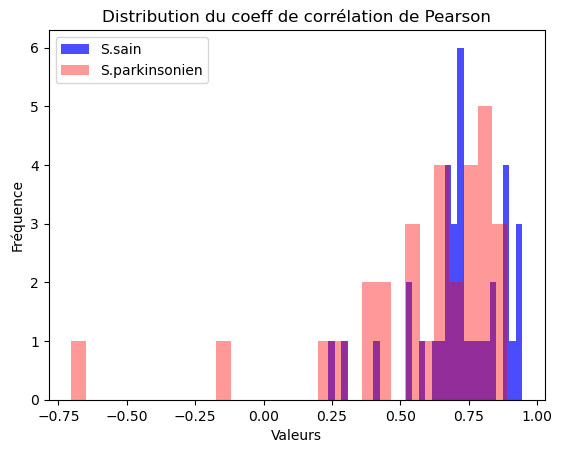

In [ ]:
# Tracer les histogrammes
plt.hist(liste_corr, bins=30, alpha=0.7, label='S.sain', color='blue')  # Histogramme 1
plt.hist(liste_corr2,bins=30, alpha=0.4, label='S.parkinsonien',color='red')  # Histogramme 2

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Distribution du coeff de corrélation de Pearson')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure8.png")

# Afficher la figure
plt.show()

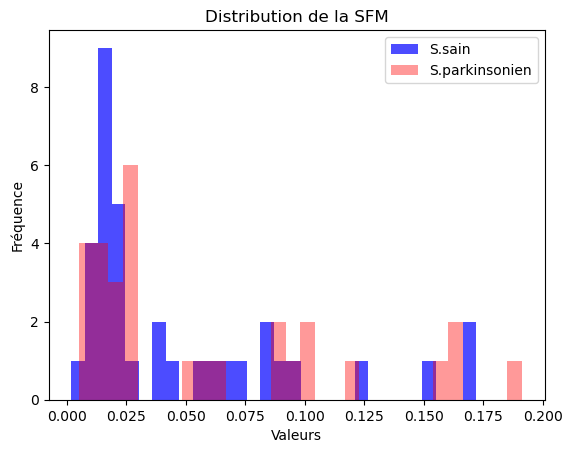

In [ ]:
# Tracer les histogrammes
plt.hist(liste_SFM, bins=30, alpha=0.7, label='S.sain', color='blue')  # Histogramme 1
plt.hist(liste_SFM2,bins=30, alpha=0.4, label='S.parkinsonien',color='red')  # Histogramme 2

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Distribution de la SFM')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/hist SFM.png")

# Afficher la figure
plt.show()

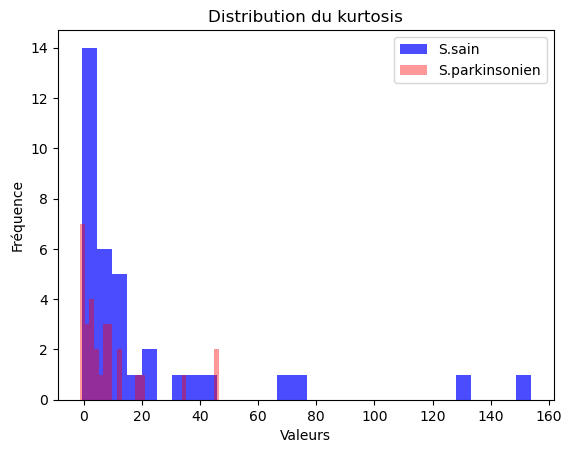

In [ ]:
# Tracer les histogrammes
plt.hist(kurt, bins=30, alpha=0.7, label='S.sain', color='blue')  # Histogramme 1
plt.hist(kurt2,bins=30, alpha=0.4, label='S.parkinsonien',color='red')  # Histogramme 2

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Distribution du kurtosis')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/hist kurt.png")

# Afficher la figure
plt.show()

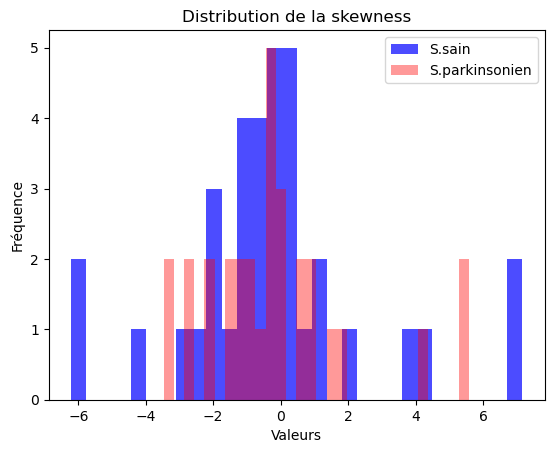

In [ ]:
# Tracer les histogrammes
plt.hist(skew, bins=30, alpha=0.7, label='S.sain', color='blue')  # Histogramme 1
plt.hist(skew2,bins=30, alpha=0.4, label='S.parkinsonien',color='red')  # Histogramme 2

# Ajouter des légendes
plt.legend()

# Ajouter des titres et des labels d'axes
plt.title('Distribution de la skewness')
plt.xlabel('Valeurs')
plt.ylabel('Fréquence')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/hist skew.png")

# Afficher la figure
plt.show()

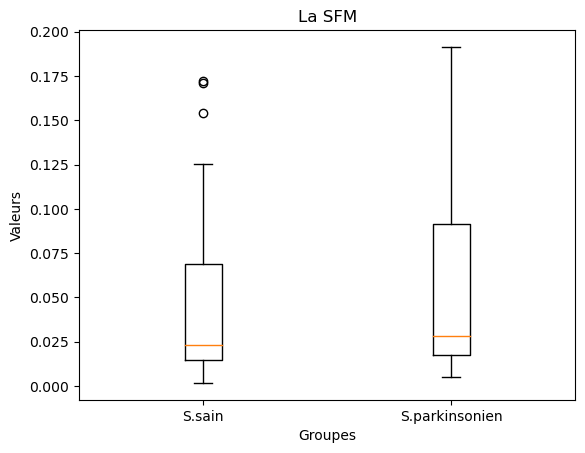

In [ ]:
# Tracer les boîtes à moustaches
plt.boxplot([liste_SFM, liste_SFM2], labels=['S.sain', 'S.parkinsonien'])

# Ajouter des titres et des labels d'axes
plt.title('La SFM')
plt.xlabel('Groupes')
plt.ylabel('Valeurs')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure9.png")

# Afficher la figure
plt.show()

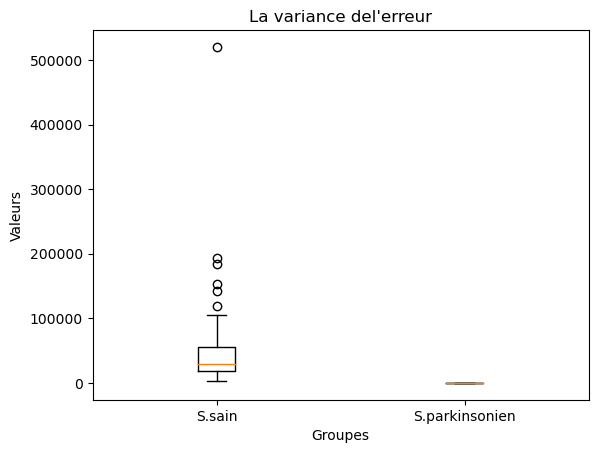

In [ ]:
# Tracer les boîtes à moustaches
plt.boxplot([var, var2], labels=['S.sain', 'S.parkinsonien'])

# Ajouter des titres et des labels d'axes
plt.title("La variance del'erreur")
plt.xlabel('Groupes')
plt.ylabel('Valeurs')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/var box.png")

# Afficher la figure
plt.show()

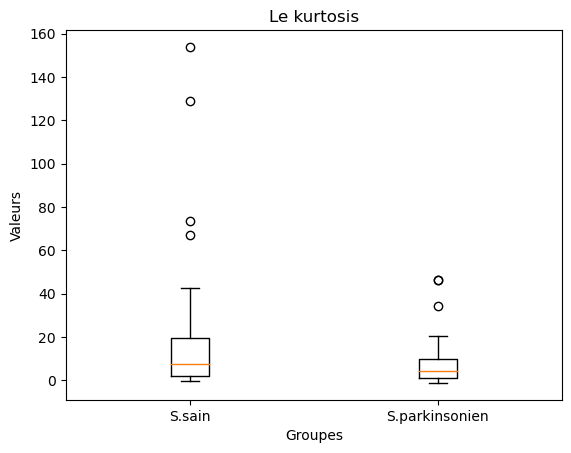

In [ ]:
# Tracer les boîtes à moustaches
plt.boxplot([kurt, kurt2], labels=['S.sain', 'S.parkinsonien'])

# Ajouter des titres et des labels d'axes
plt.title('Le kurtosis')
plt.xlabel('Groupes')
plt.ylabel('Valeurs')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure10.png")

# Afficher la figure
plt.show()

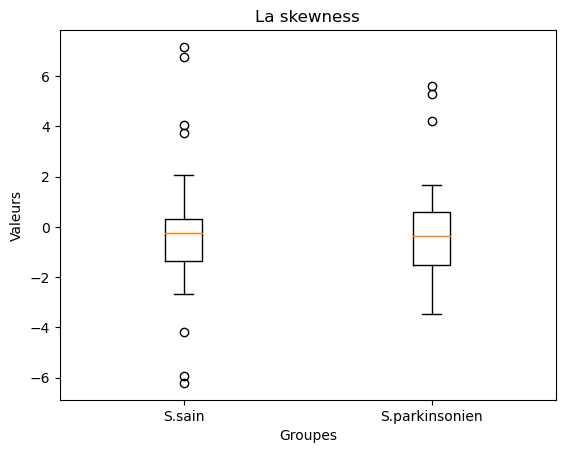

In [ ]:
# Tracer les boîtes à moustaches
plt.boxplot([skew, skew2], labels=['S.sain', 'S.parkinsonien'])

# Ajouter des titres et des labels d'axes
plt.title('La skewness')
plt.xlabel('Groupes')
plt.ylabel('Valeurs')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure11.png")

# Afficher la figure
plt.show()

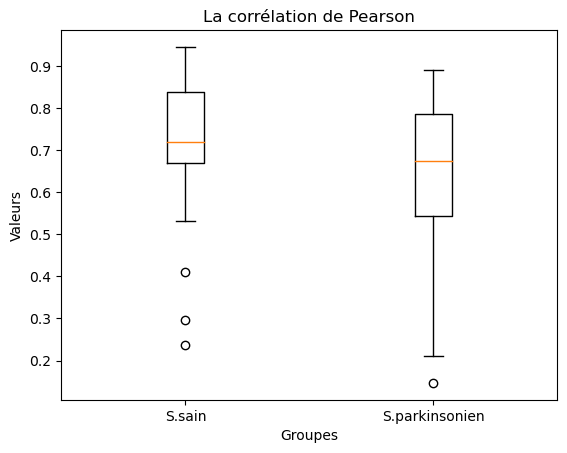

In [ ]:
# Tracer les boîtes à moustaches
plt.boxplot([np.abs(liste_corr), np.abs(liste_corr2)], labels=['S.sain', 'S.parkinsonien'])

# Ajouter des titres et des labels d'axes
plt.title('La corrélation de Pearson')
plt.xlabel('Groupes')
plt.ylabel('Valeurs')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure12.png")

# Afficher la figure
plt.show()

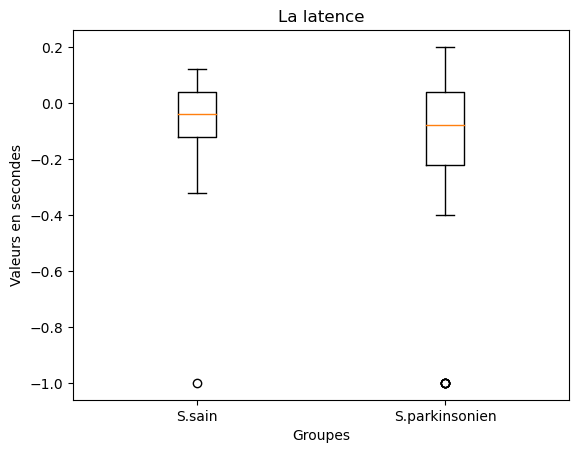

In [ ]:
# Tracer les boîtes à moustaches
plt.boxplot([liste_delay, liste_delay2], labels=['S.sain', 'S.parkinsonien'])

# Ajouter des titres et des labels d'axes
plt.title('La latence')
plt.xlabel('Groupes')
plt.ylabel('Valeurs en secondes')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure88.png")

# Afficher la figure
plt.show()

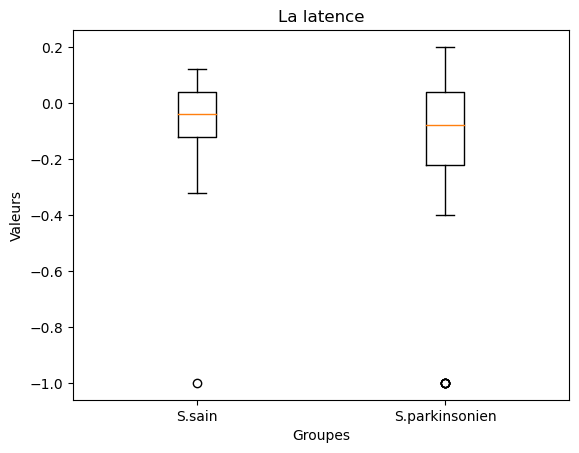

In [ ]:
# Limiter les valeurs entre 5 et -5
liste_delay = [max(min(x, 1), -1) for x in liste_delay]
liste_delay2 = [max(min(x, 1), -1) for x in liste_delay2]

# Tracer les boîtes à moustaches
plt.boxplot([liste_delay, liste_delay2], labels=['S.sain', 'S.parkinsonien'])

# Ajouter des titres et des labels d'axes
plt.title('La latence')
plt.xlabel('Groupes')
plt.ylabel('Valeurs')
plt.savefig("C:/Users/nadam/OneDrive/Bureau/PD-HC/comparaison des descripteurs/figure55.png")

# Afficher la figure
plt.show()


## Création de nouvelle base de données

In [ ]:
len(liste_corr2)

30

In [ ]:
Corr_pearson=np.abs(liste_corr+liste_corr2)

In [ ]:
len(Corr_pearson)

65

In [ ]:
v=var+var2
k=kurt+kurt2
s=skew+skew2

In [ ]:
len(s)

65

In [ ]:
vc=[]
for i in range (30):
    vc.append(0)# 0 for healthy
for i in range(30,65):
    vc.append(1)# 1 for parkinsonian

In [ ]:
len(vc)

65

In [ ]:
# Créer un DataFrame avec vos données
data = {
    'Delay': delay,
    'SFM': SFM,
    'Corr de pearson': Corr_pearson,
    'Variance': v,
    'Kurtosis': k,
    'Skewness':s,
    'variable cible':vc
}
df = pd.DataFrame(data)

# Spécifier le chemin vers le fichier Excel où vous voulez sauvegarder les données
nom_fichier_excel = "E:/bbd final.xlsx"

# Écrire les données dans le fichier Excel
df.to_excel(nom_fichier_excel, index=False)

print("Base de données créée avec succès dans", nom_fichier_excel)

Base de données créée avec succès dans E:/bbd final.xlsx


#### Classification K-means

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Chargez votre base de données de descripteurs dans un DataFrame pandas (remplacez ceci par votre propre chargement de données)
data = pd.read_excel("E:/Base de descripteurs.xlsx")



# Supposons que vous avez une colonne "descripteurs" contenant vos descripteurs
X = data.drop(columns=["variable cible"])  # Supprimez la colonne cible si vous en avez une

# Normalisez vos données pour garantir que chaque descripteur a une variance unitaire et une moyenne nulle
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Spécifiez le nombre de clusters
nombre_de_clusters = 2

# Créez un objet KMeans
kmeans = KMeans(n_clusters=nombre_de_clusters)

# Exécutez l'algorithme K-means sur les données
kmeans.fit(X_scaled)

# Obtenez les centroids finaux
centroids = kmeans.cluster_centers_

# Obtenez les labels de cluster pour chaque point de données
labels = kmeans.labels_

# Ajoutez les labels de cluster à votre DataFrame
data["cluster"] = labels

# Affichez les statistiques de chaque cluster si nécessaire
cluster_stats = data.groupby("cluster").describe()

# Affichez les résultats
print("Centroids:")
print(centroids)
print("\nLabels:")
print(labels)
print("\nCluster Statistics:")
print(cluster_stats)


C:\Users\nadam\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\nadam\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1436: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Centroids:
[[-0.04750341 -0.38975762  0.36933042 -0.25565794 -0.16415867  0.14648432]
 [ 0.17417917  1.42911127 -1.35421153  0.93741244  0.60191513 -0.53710916]]

Labels:
[0 0 0 0 0 1 0 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 1 0 0]

Cluster Statistics:
        Delay                                                     SFM  \
        count      mean       std   min   25%   50%   75%   max count   
cluster                                                                 
0        55.0 -0.142545  0.642438 -3.40 -0.12  0.00  0.06   0.2  55.0   
1        15.0  0.533333  6.670921 -8.32 -0.34 -0.08  0.10  22.6  15.0   

                   ...  Skewness           variable cible                      \
             mean  ...       75%       max          count      mean       std   
cluster            ...                                                          
0        0.033821  ...  0.354888  7.159344           55.

In [ ]:
liste_SFM[6]

0.04270356449285152